# v3 (blind) — Algorithms on the Synthetic FD Model

Visual comparison of Random Search, Hill Climbing and Tabu Search on the
two finite-difference cases of the synthetic layered model
(`notebooks/synthetic_models/fd_layered_model.ipynb`): `fd_layered_cdp2500_fs`
(with free-surface multiples) and `fd_layered_cdp2500_nofs` (without).

Same blind objective (v3, formulation `threshold`) and the same budget
(100,000 evaluations) used in `v3_threshold_free_k/comparison` for
Marmousi2, but evaluated against the **semblance peak of each expected
event** instead of the model V_rms (see the fd_layered notebook, section
10, and `src/analysis/reference.py`), since on finite-difference data the
blob sits 1-3% off the model velocity.

**Execution order:**
1. Setup
2. Parameters
3. Load the cases and their reference picks
4. Run the three algorithms on each case
5. Visual comparison: picks on the semblance panel
6. Convergence (best f vs. evaluations)
7. Table of results
8. Save results
9. Summary


## 1. Setup

In [1]:
import sys
import os
import json
import numpy as np
import matplotlib.pyplot as plt

# Project root: walk up to the folder that contains src/
from pathlib import Path
project_root = Path.cwd().resolve()
while not (project_root / 'src').is_dir():
    if project_root.parent == project_root:
        raise RuntimeError('Project root (folder containing src/) not found.')
    project_root = project_root.parent
project_root = str(project_root)
if project_root not in sys.path:
    sys.path.insert(0, project_root)

print(f'Project root: {project_root}')


Project root: /home/rafael-garcia/projetos/seismic-velocity-picking


In [2]:
from src.seismic.cases     import load_case
from src.seismic.semblance import compute_semblance, robust_threshold, picking_objective_threshold
from src.analysis.reference import match_reference
from src.optimizers.random_search import RandomSearch
from src.optimizers.hill_climbing import HillClimbing
from src.optimizers.tabu_search   import TabuSearch

print('All modules imported successfully.')


All modules imported successfully.


## 2. Parameters

In [3]:
# --- Cases: the synthetic 2D model, with and without free-surface multiples ---
CASES = ['fd_layered_cdp2500_fs', 'fd_layered_cdp2500_nofs']
LABEL = {'fd_layered_cdp2500_fs':   'with free surface (multiples)',
         'fd_layered_cdp2500_nofs': 'without free surface (no multiples)'}

# --- Blind formulation v3 (same as v3_threshold_free_k/comparison) ---
VEL_MIN      = 1400.0        # water velocity as the floor
VEL_MAX      = 5000.0        # generous ceiling
VEL_STEP     = 20.0          # velocity increment of the panel used for tau
MIN_SEP_MS   = 100.0         # minimum separation between picks
TAU_FACTOR   = 10.0          # tau = median + TAU_FACTOR * sigma_rob of the panel

# --- Moves that change the number of picks (all algorithms) ---
P_INSERT     = 0.1
P_REMOVE     = 0.1

# --- Budget (same for every algorithm and every case: the whole point of
# the comparison is a fair budget) ---
MAX_EVALS    = 100000
SEED         = 42

# --- Local moves (Hill Climbing and Tabu Search) ---
STEP_TIME    = 5
STEP_VEL     = 50.0
N_NEIGHBORS  = 30
MAX_ITER     = 3 * MAX_EVALS // N_NEIGHBORS

# --- Hill Climbing ---
HC_PATIENCE  = 60
HC_RESTARTS  = 10**6

# --- Tabu Search ---
TABU_TENURE  = 15
P_JUMP       = 0.1
TS_PATIENCE  = MAX_ITER

# --- Evaluation only (reference, not seen by the algorithms) ---
VEL_TOL      = 0.02          # relative velocity tolerance against the reference peak
TIME_TOL_MS  = 40.0          # same window used to find the reference peaks


## 3. Load the cases and their reference picks

Each `fd_*` case already carries `meta['reference_picks']`: the semblance
peak found near every primary and, when the free surface is on, every
surface multiple (`scripts/add_reference_picks.py`). That is the
evaluation target — see `notebooks/synthetic_models/fd_layered_model.ipynb`,
section 10, for why the peak and not the model V_rms is used.


In [4]:
data = {}
for name in CASES:
    case = load_case(os.path.join(project_root, 'cases', f'{name}.npz'))
    velocities = np.arange(VEL_MIN, VEL_MAX + VEL_STEP, VEL_STEP, dtype=np.float32)
    panel = compute_semblance(case['gather'], case['offsets'], velocities, case['dt_ms'])
    tau   = robust_threshold(panel, factor=TAU_FACTOR)
    reference = case['meta']['reference_picks']
    primaries = [r for r in reference if r['kind'] == 'primary']

    # Best achievable objective using only the primary reference points
    # (a lower bound: a real run may also land, by chance, on a multiple)
    ref_picks = [(int(round(r['t_ms'] / case['dt_ms'])), r['v']) for r in primaries]
    f_ref = picking_objective_threshold(case['gather'], case['offsets'], ref_picks,
                                        case['dt_ms'], tau)

    data[name] = {'case': case, 'panel': panel, 'velocities': velocities,
                  'tau': tau, 'reference': reference, 'f_ref': f_ref}
    print(f'{name:28s}  tau = {tau:.3f}   primaries = {len(primaries)}   '
          f'multiples = {len(reference) - len(primaries)}   f_ref = {f_ref:.3f}')


fd_layered_cdp2500_fs         tau = 0.195   primaries = 4   multiples = 5   f_ref = 1.158
fd_layered_cdp2500_nofs       tau = 0.163   primaries = 4   multiples = 0   f_ref = 1.049


## 4. Run the three algorithms on each case

In [5]:
results = {}
for name in CASES:
    d = data[name]
    c = d['case']
    common = dict(
        traces=c['gather'], offsets=c['offsets'], dt_ms=c['dt_ms'],
        vel_min=VEL_MIN, vel_max=VEL_MAX, min_sep_ms=MIN_SEP_MS,
        objective='threshold', tau=d['tau'], p_insert=P_INSERT, p_remove=P_REMOVE,
        seed=SEED, max_evals=MAX_EVALS,
    )
    local = dict(step_time=STEP_TIME, step_vel=STEP_VEL,
                 n_neighbors=N_NEIGHBORS, max_iter=MAX_ITER)
    algorithms = {
        'Random Search': lambda: RandomSearch(**common),
        'Hill Climbing': lambda: HillClimbing(**common, **local,
                                              restarts=HC_RESTARTS, patience=HC_PATIENCE),
        'Tabu Search':   lambda: TabuSearch(**common, **local, tabu_tenure=TABU_TENURE,
                                            patience=TS_PATIENCE, p_jump=P_JUMP),
    }

    print(f'--- {name} ({LABEL[name]}) ---')
    case_results = {}
    for alg_name, make in algorithms.items():
        opt = make().run()
        t_s, v_s = opt.get_result()
        case_results[alg_name] = {'opt': opt, 'times_ms': t_s * c['dt_ms'], 'vels': v_s}
        print(f'  {alg_name:>14s}   f = {opt.best_score:.3f}   K = {len(t_s)}   '
              f'evals = {opt.n_evals}   time = {opt.exec_time_s:.1f} s')
    results[name] = case_results
    print()


--- fd_layered_cdp2500_fs (with free surface (multiples)) ---
   Random Search   f = 0.389   K = 1   evals = 100000   time = 176.5 s
   Hill Climbing   f = 1.202   K = 6   evals = 100000   time = 49.6 s
     Tabu Search   f = 1.470   K = 6   evals = 100000   time = 54.6 s

--- fd_layered_cdp2500_nofs (without free surface (no multiples)) ---
   Random Search   f = 0.309   K = 2   evals = 100000   time = 155.7 s
   Hill Climbing   f = 2.133   K = 9   evals = 100000   time = 70.9 s
     Tabu Search   f = 2.097   K = 9   evals = 100000   time = 85.4 s



## 5. Visual comparison: picks on the semblance panel

`o` / `+`: the reference pair (model position / semblance peak) from
section 3, white for a primary, magenta for a multiple. Each algorithm's
picks are colored by what they matched (`src.analysis.reference.match_reference`):
black circle = landed on a primary, orange X = landed on a (real but
unwanted) multiple, red X = matched nothing.


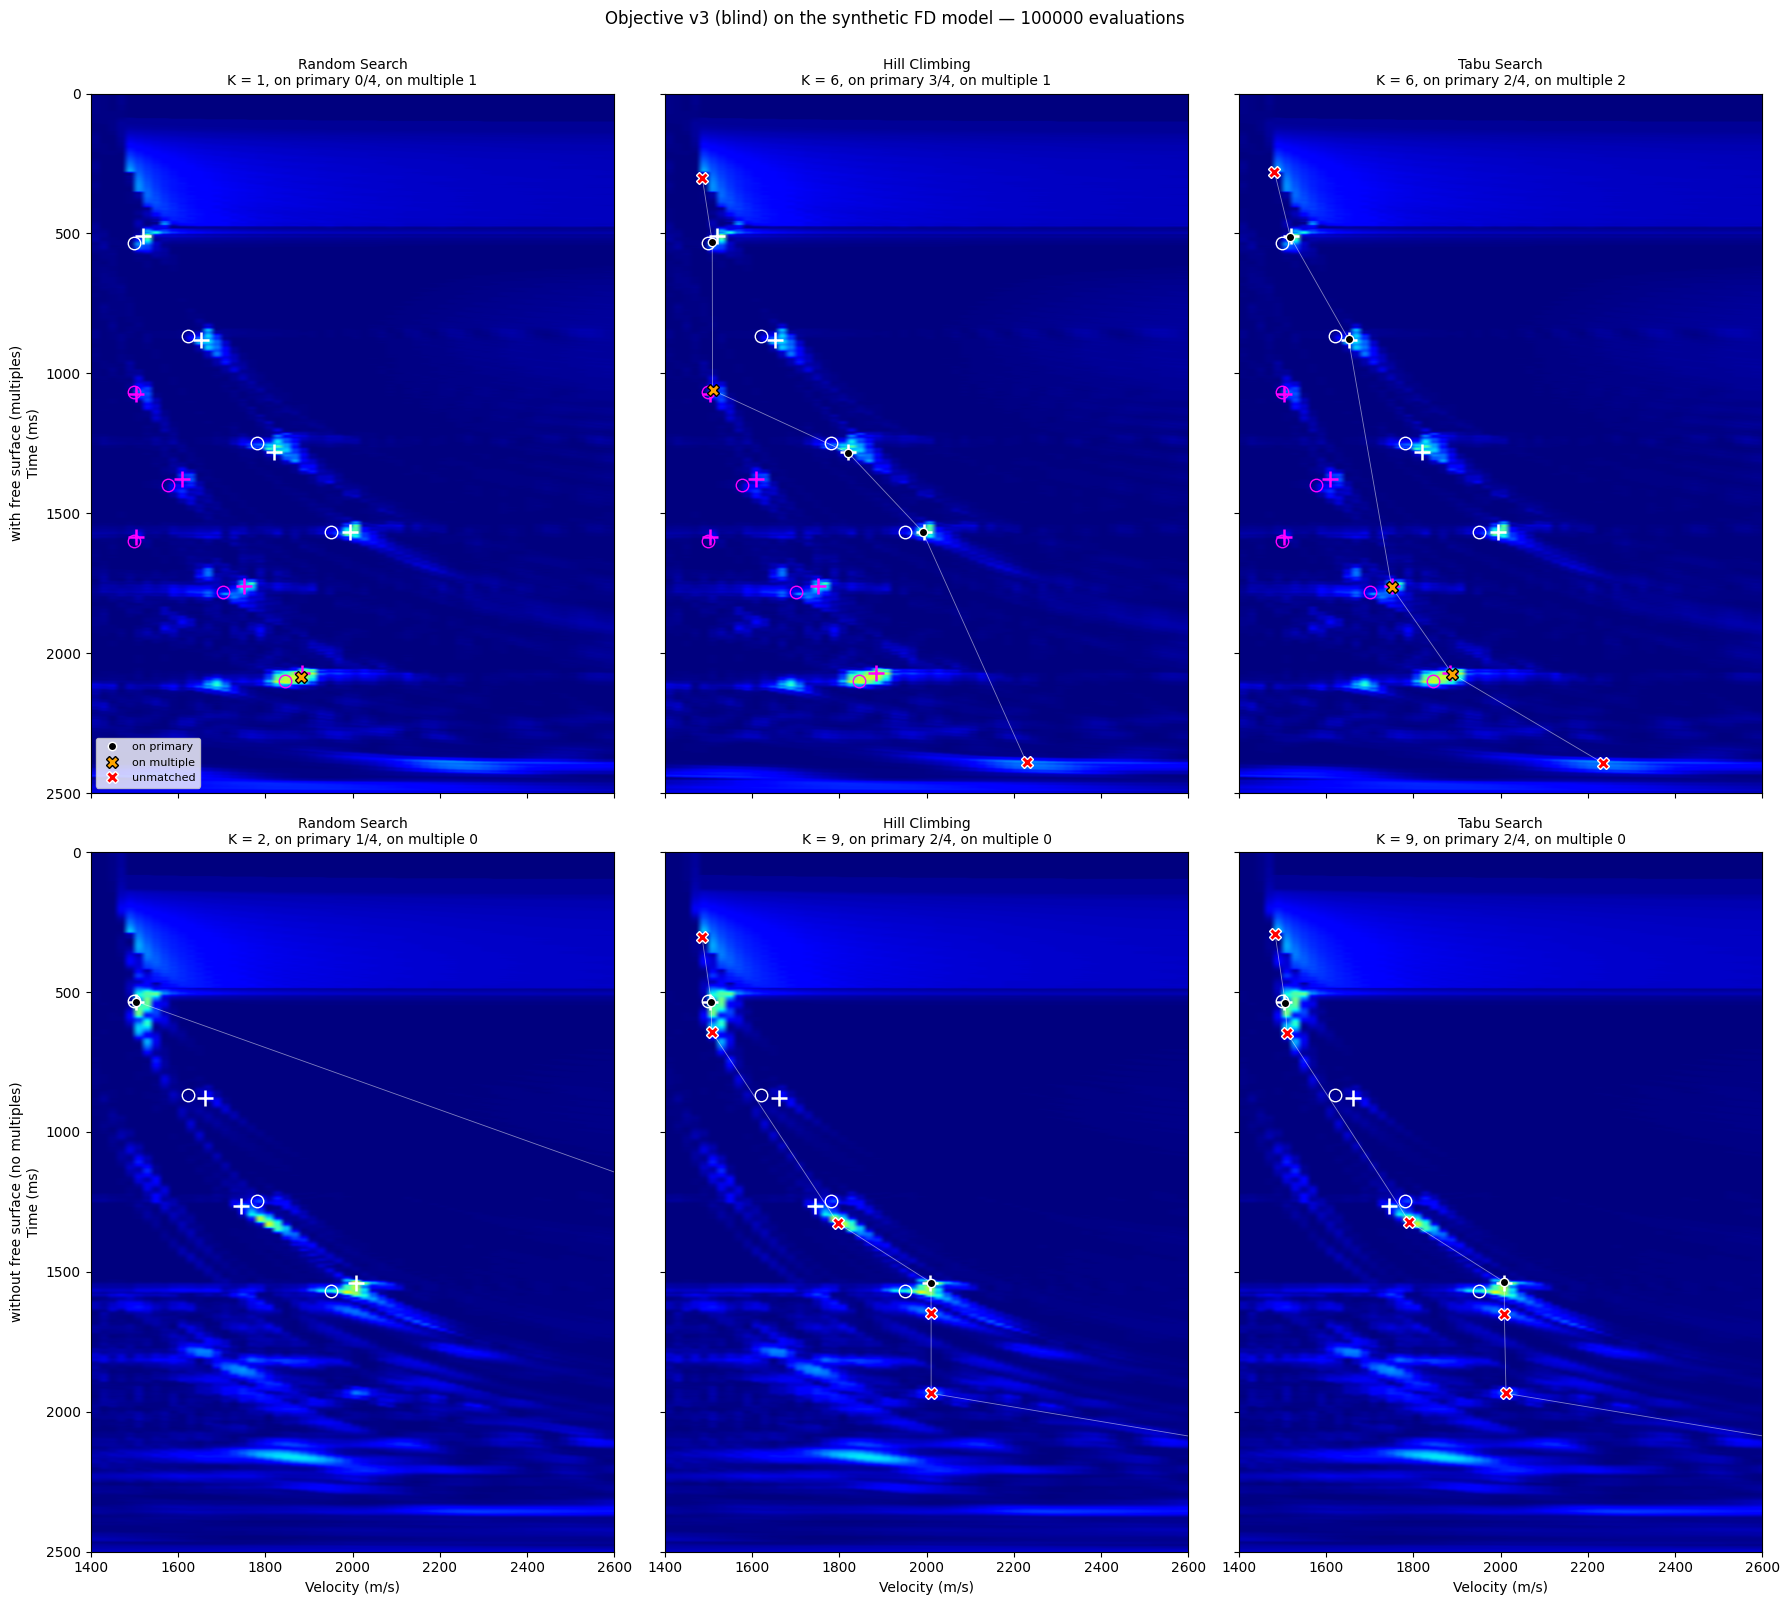

In [6]:
os.makedirs(os.path.join(project_root, 'results', 'figures'), exist_ok=True)

fig, axes = plt.subplots(len(CASES), 3, figsize=(18, 8 * len(CASES)), sharex=True, sharey=True)
if len(CASES) == 1:
    axes = axes[None, :]

for row, name in enumerate(CASES):
    d, c = data[name], data[name]['case']
    t_grid = c['t_grid']

    for col, (alg_name, r) in enumerate(results[name].items()):
        ax = axes[row, col]
        m = match_reference(r['times_ms'], r['vels'], d['reference'],
                            time_tol_ms=TIME_TOL_MS, vel_tol=VEL_TOL)
        kind = np.array(m['kind'])
        on_primary  = kind == 'primary'
        on_multiple = kind == 'multiple'
        unmatched   = ~on_primary & ~on_multiple

        ax.imshow(d['panel'].T, aspect='auto', cmap='jet', vmin=0, vmax=1,
                  extent=[VEL_MIN, VEL_MAX, t_grid[-1], t_grid[0]])
        for ref in d['reference']:
            color = 'white' if ref['kind'] == 'primary' else 'magenta'
            ax.plot(ref['v_model'], ref['t0_ms'], 'o', mfc='none', mec=color,
                    markersize=9, mew=1.0)
            ax.plot(ref['v'], ref['t_ms'], '+', color=color, markersize=12, mew=1.8)

        ax.plot(r['vels'], r['times_ms'], 'w-', linewidth=0.6, alpha=0.5)
        ax.plot(np.array(r['vels'])[on_primary], np.array(r['times_ms'])[on_primary],
                'o', color='black', markeredgecolor='white', markersize=6, label='on primary')
        ax.plot(np.array(r['vels'])[on_multiple], np.array(r['times_ms'])[on_multiple],
                'X', color='orange', markeredgecolor='black', markersize=8, label='on multiple')
        ax.plot(np.array(r['vels'])[unmatched], np.array(r['times_ms'])[unmatched],
                'X', color='red', markeredgecolor='white', markersize=8, label='unmatched')

        ax.set_xlim(VEL_MIN, 2600)
        ax.set_title(f"{alg_name}\nK = {m['n_picks']}, on primary {m['n_on_primary']}/"
                    f"{m['n_primaries']}, on multiple {m['n_on_multiple']}", fontsize=10)
        if row == len(CASES) - 1:
            ax.set_xlabel('Velocity (m/s)')
    axes[row, 0].set_ylabel(f"{LABEL[name]}\nTime (ms)")

axes[0, 0].legend(loc='lower left', fontsize=8)
plt.suptitle(f'Objective v3 (blind) on the synthetic FD model — {MAX_EVALS} evaluations', y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(project_root, 'results', 'figures', 'fd_model_visual_comparison.png'),
           dpi=150, bbox_inches='tight')
plt.show()


## 6. Convergence (best f vs. evaluations)

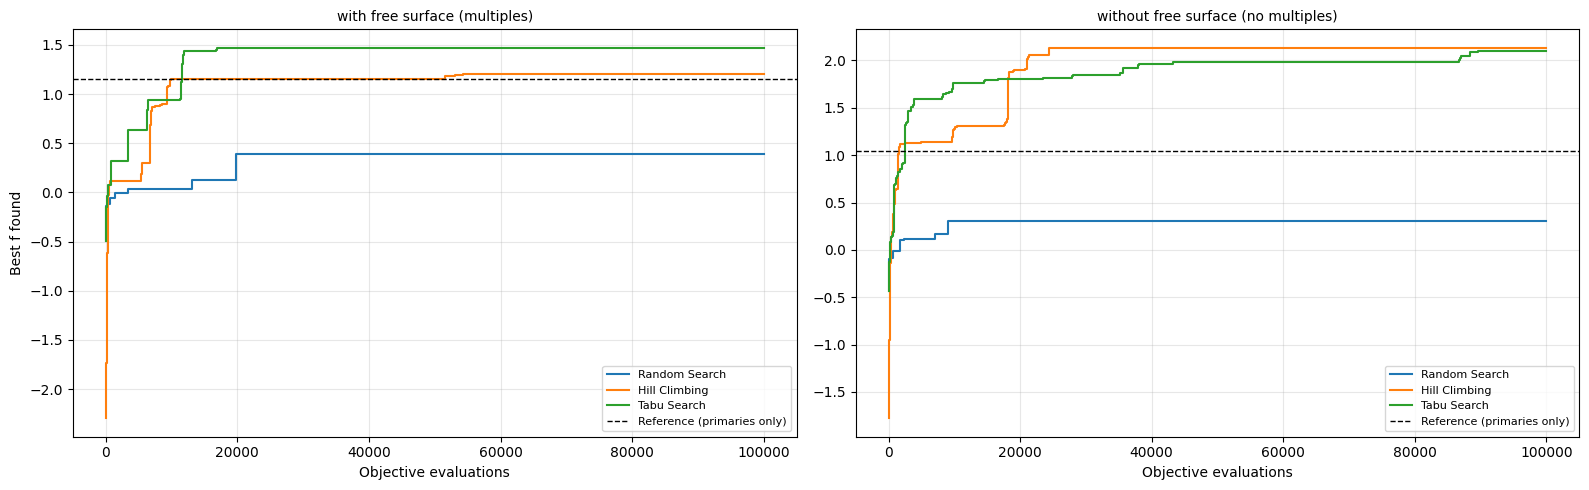

In [7]:
fig, axes = plt.subplots(1, len(CASES), figsize=(8 * len(CASES), 5), sharey=False)
if len(CASES) == 1:
    axes = [axes]

for ax, name in zip(axes, CASES):
    for alg_name, r in results[name].items():
        opt = r['opt']
        hist = opt.eval_history
        x = [e for e, _ in hist] + [opt.n_evals]
        y = [f for _, f in hist] + [hist[-1][1]]
        ax.step(x, y, where='post', linewidth=1.5, label=alg_name)
    ax.axhline(data[name]['f_ref'], color='black', linestyle='--', linewidth=1.0,
              label='Reference (primaries only)')
    ax.set_xlabel('Objective evaluations')
    ax.set_title(LABEL[name], fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Best f found')
plt.tight_layout()
plt.savefig(os.path.join(project_root, 'results', 'figures', 'fd_model_convergence.png'), dpi=150)
plt.show()


## 7. Table of results

In [8]:
rows = {}
for name in CASES:
    d = data[name]
    rows[name] = {}
    for alg_name, r in results[name].items():
        m = match_reference(r['times_ms'], r['vels'], d['reference'],
                            time_tol_ms=TIME_TOL_MS, vel_tol=VEL_TOL)
        rows[name][alg_name] = {
            'f': float(r['opt'].best_score), 'K': m['n_picks'],
            'n_on_primary': m['n_on_primary'], 'n_primaries': m['n_primaries'],
            'n_on_multiple': m['n_on_multiple'],
            'precision': m['precision'], 'recall': m['recall'], 'f1': m['f1'],
            'n_evals': r['opt'].n_evals, 'exec_time_s': float(r['opt'].exec_time_s),
        }

for name in CASES:
    print(f'=== {name} ({LABEL[name]}) ===')
    print(f'{"Algorithm":>14} {"f":>8} {"f_ref":>8} {"K":>4} {"on prim":>8} '
          f'{"on mult":>8} {"Prec.":>6} {"Recall":>7} {"F1":>5} {"Time (s)":>9}')
    print('-' * 86)
    for alg_name, m in rows[name].items():
        print(f"{alg_name:>14} {m['f']:>8.3f} {data[name]['f_ref']:>8.3f} {m['K']:>4} "
              f"{m['n_on_primary']:>4}/{m['n_primaries']:<3} {m['n_on_multiple']:>8} "
              f"{m['precision']:>6.0%} {m['recall']:>7.0%} {m['f1']:>5.2f} {m['exec_time_s']:>9.1f}")
    print()

print('"on prim"/"on mult": picks matched (within 40 ms and 2% velocity) to a')
print('semblance peak of a primary / of a multiple. "f_ref": objective reachable')
print('by picking exactly the primary reference points (a lower bound).')


=== fd_layered_cdp2500_fs (with free surface (multiples)) ===
     Algorithm        f    f_ref    K  on prim  on mult  Prec.  Recall    F1  Time (s)
--------------------------------------------------------------------------------------
 Random Search    0.389    1.158    1    0/4          1     0%      0%  0.00     176.5
 Hill Climbing    1.202    1.158    6    3/4          1    50%     75%  0.60      49.6
   Tabu Search    1.470    1.158    6    2/4          2    33%     50%  0.40      54.6

=== fd_layered_cdp2500_nofs (without free surface (no multiples)) ===
     Algorithm        f    f_ref    K  on prim  on mult  Prec.  Recall    F1  Time (s)
--------------------------------------------------------------------------------------
 Random Search    0.309    1.049    2    1/4          0    50%     25%  0.33     155.7
 Hill Climbing    2.133    1.049    9    2/4          0    22%     50%  0.31      70.9
   Tabu Search    2.097    1.049    9    2/4          0    22%     50%  0.31      85

## 8. Save results

In [9]:
os.makedirs(os.path.join(project_root, 'results', 'metrics'), exist_ok=True)

summary = {
    'cases': CASES,
    'formulation': {'vel_min': VEL_MIN, 'vel_max': VEL_MAX, 'min_sep_ms': MIN_SEP_MS,
                    'tau_factor': TAU_FACTOR, 'p_insert': P_INSERT, 'p_remove': P_REMOVE},
    'max_evals': MAX_EVALS, 'seed': SEED,
    'results': {
        name: {
            'tau': data[name]['tau'], 'f_ref': data[name]['f_ref'],
            'algorithms': {alg_name: {**rows[name][alg_name],
                                      'times_ms': results[name][alg_name]['times_ms'].tolist(),
                                      'vels': results[name][alg_name]['vels'].tolist()}
                          for alg_name in rows[name]},
        }
        for name in CASES
    },
}

path = os.path.join(project_root, 'results', 'metrics', 'fd_model_visual.json')
with open(path, 'w') as f:
    json.dump(summary, f, indent=2)
print(f'Results saved: {path}')


Results saved: /home/rafael-garcia/projetos/seismic-velocity-picking/results/metrics/fd_model_visual.json


## 9. Summary

This is a **single-seed visual check** of the three algorithms on the
synthetic FD model, with the same budget (100,000 evaluations) used on
both the case with free-surface multiples and the case without them.
It answers "does each algorithm behave sensibly here", not "which
algorithm is better" — that needs several seeds and a statistical test,
done next with the batch runner (`scripts/run_batch.py`).

**What to look for:**
- picks on a multiple (orange X) only happen in the `fs` case — the
  `nofs` case has no multiples to be fooled by, so it is the easier of
  the two;
- the reference peak of `top A` in the `nofs` case sits below tau (see
  `notebooks/synthetic_models/fd_layered_model.ipynb`, section 10): no
  algorithm can reach it, so a recall of 3/4 there is already the
  ceiling, not a search failure;
- the dashed reference line in the convergence plot is reachable in
  principle (it is built from real picks) but not necessarily found —
  an algorithm converging below it has room to improve; one converging
  close to it, or above it (by also catching a multiple), has little.

**Next step.** The robust comparison runs from the terminal, as in the
first report: `python scripts/run_batch.py configs/batch_fd_model.json`
repeats the same three algorithms over several seeds on both cases, with
the same budget, and compares them with a paired Wilcoxon signed-rank
test (same seeds for every algorithm).
